Skewness: 2.8770611473024483
Mean delivery time: 34.541809523809526
Median delivery time: 32.5


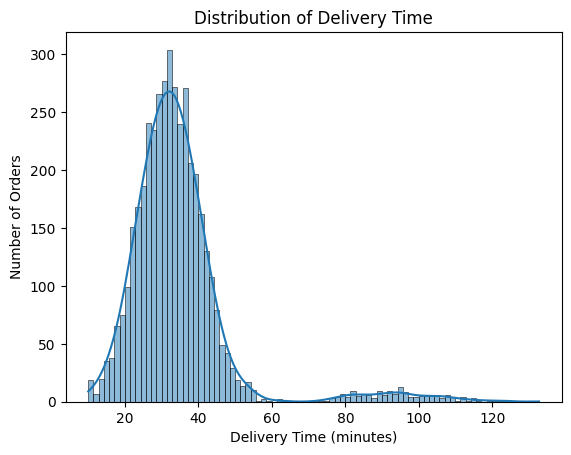

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

df = pd.read_csv("food_delivery_orders.csv")

skewness = df['delivery_time_min'].skew()
mean_delivery = df['delivery_time_min'].mean()
median_delivery = df['delivery_time_min'].median()

print("Skewness:", skewness)
print("Mean delivery time:", mean_delivery)
print("Median delivery time:", median_delivery)

sns.histplot(data=df, x='delivery_time_min', kde=True)

plt.xlabel("Delivery Time (minutes)")
plt.ylabel("Number of Orders")
plt.title("Distribution of Delivery Time")
plt.show()

# The skewness is +2.877, which is strongly positive.
# The delivery-time distribution is strongly right-skewed (skewness = 2.877), with a mean of 34.54 minutes and a median of 32.50 minutes. 
# The median is the more honest number to advertise because it is less affected by unusually long deliveries and better represents the typical order.

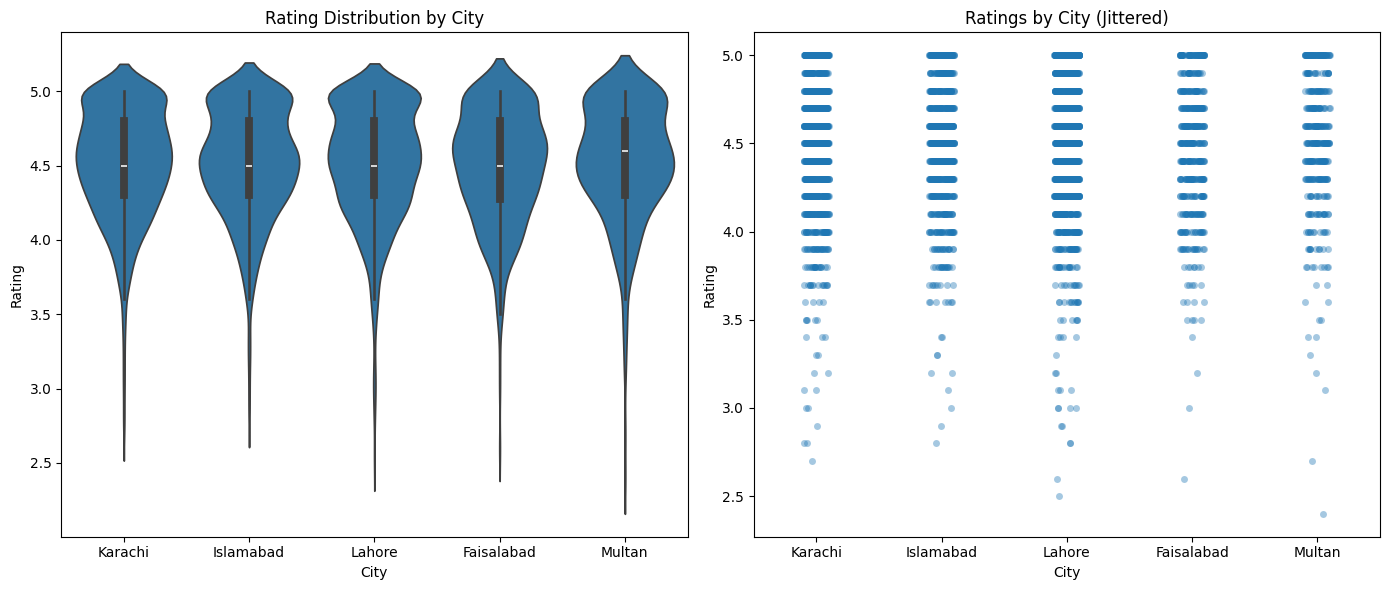

In [16]:
#Task 2
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.violinplot(data=df, x='city', y='rating')
plt.title("Rating Distribution by City")
plt.xlabel("City")
plt.ylabel("Rating")

plt.subplot(1, 2, 2)
sns.stripplot(data=df, x='city', y='rating', jitter=True, alpha=0.4)
plt.title("Ratings by City (Jittered)")
plt.xlabel("City")
plt.ylabel("Rating")

plt.tight_layout()
plt.show()

# Multan shows the most inconsistent customer experience because its ratings have the widest spread. 
# The large variation in ratings indicates that customer experiences differ more widely in Multan than in the other cities.

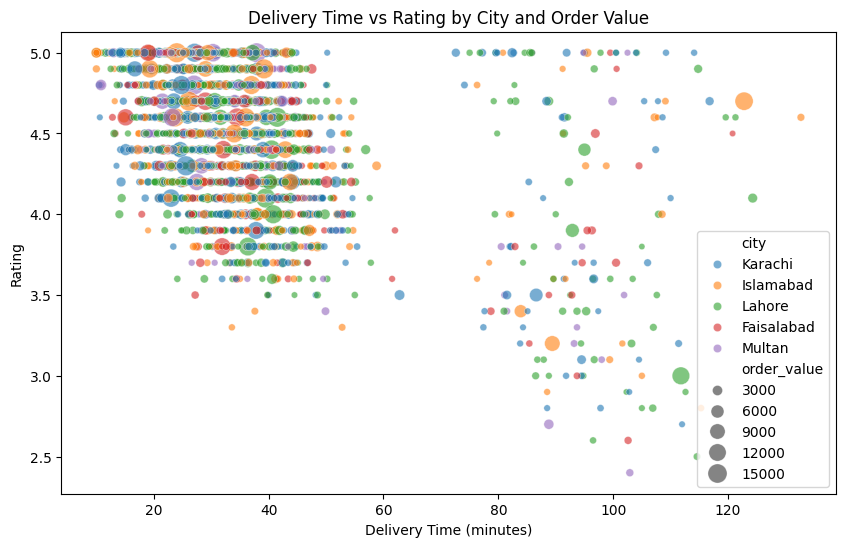

In [17]:
#Task 3
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='delivery_time_min',
    y='rating',
    hue='city',
    size='order_value',
    sizes=(20, 200),
    alpha=0.6
)

plt.title("Delivery Time vs Rating by City and Order Value")
plt.xlabel("Delivery Time (minutes)")
plt.ylabel("Rating")
plt.show()

# High-value orders (larger bubbles) are mostly concentrated around shorter delivery times, generally below about 50 minutes,
# and many of them have relatively high ratings (around 4–5). 
# This suggests that higher-value orders tend to receive faster delivery and relatively better ratings.

Pearson Correlation Matrix:


,order_value,discount_percent,delivery_time_min,rating,profit_per_order
order_value,1.000000,-0.011191,0.002202,0.003122,-0.657144
discount_percent,-0.011191,1.000000,0.013286,-0.006129,-0.081982
delivery_time_min,0.002202,0.013286,1.000000,-0.445474,-0.030879
rating,0.003122,-0.006129,-0.445474,1.000000,0.014360
profit_per_order,-0.657144,-0.081982,-0.030879,0.014360,1.000000



Spearman Correlation Matrix:


,order_value,discount_percent,delivery_time_min,rating,profit_per_order
order_value,1.000000,0.007783,-0.020271,0.004487,0.673114
discount_percent,0.007783,1.000000,0.019502,-0.002619,-0.380515
delivery_time_min,-0.020271,0.019502,1.000000,-0.412735,-0.108586
rating,0.004487,-0.002619,-0.412735,1.000000,0.052351
profit_per_order,0.673114,-0.380515,-0.108586,0.052351,1.000000



Pair with largest disagreement: ('order_value', 'profit_per_order')
Pearson: -0.6571444205999941
Spearman: 0.673114122160055
Absolute difference: 1.330258542760049


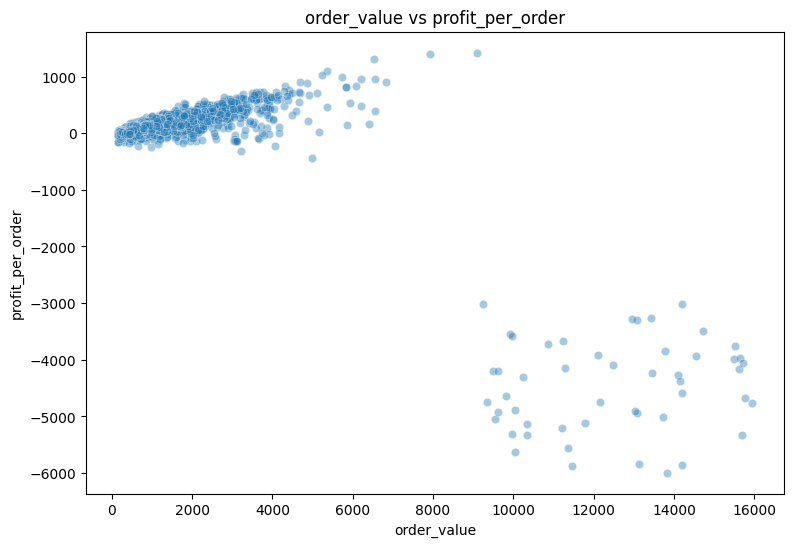


After removing extreme negative-profit orders:
Pearson: 0.7834147112756197
Spearman: 0.7343181212638537
Orders removed: 50


In [18]:
#Task 4
numeric_df = df.select_dtypes(include='number')

pearson = numeric_df.corr(method='pearson')
spearman = numeric_df.corr(method='spearman')

print("Pearson Correlation Matrix:")
display(pearson)

print("\nSpearman Correlation Matrix:")
display(spearman)

difference = (pearson - spearman).abs()

difference = difference.where(
    np.triu(np.ones(difference.shape), k=1).astype(bool)
)

pair = difference.stack().idxmax()

print("\nPair with largest disagreement:", pair)
print("Pearson:", pearson.loc[pair[0], pair[1]])
print("Spearman:", spearman.loc[pair[0], pair[1]])
print("Absolute difference:", difference.loc[pair[0], pair[1]])

x = pair[0]
y = pair[1]

plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x=x, y=y, alpha=0.4)

plt.title(f"{x} vs {y}")
plt.xlabel(x)
plt.ylabel(y)
plt.show()

clean_df = df[df['profit_per_order'] > -1000]

print("\nAfter removing extreme negative-profit orders:")
print("Pearson:", clean_df[x].corr(clean_df[y], method='pearson'))
print("Spearman:", clean_df[x].corr(clean_df[y], method='spearman'))
print("Orders removed:", len(df) - len(clean_df))

The largest disagreement is between order_value and profit_per_order: Pearson = -0.657 while Spearman = 0.673. The disagreement is mainly caused by a small number of extreme orders with very large negative profits, which strongly affect Pearson; after removing these extreme observations, both correlations become positive.

For the management decision:

These extreme orders should not automatically be dropped simply to obtain a nicer correlation. They should be investigated first; if they represent genuine orders, they are part of the business reality and should remain in the main analysis, while their unusual nature can be reported separately. If they are confirmed data-entry or system errors, then removing or correcting them is justified.

restaurant_category,Cafe,Cloud Kitchen,Dessert,Fast Food,Fine Dining,All
city,,,,,,
Faisalabad,67.295455,65.779748,-70.312281,20.222750,293.695652,51.891636
Islamabad,-13.499649,57.011427,-27.884178,37.177258,153.117851,35.491634
Karachi,-38.901838,136.745480,75.240260,15.375665,302.801418,74.101668
Lahore,52.345680,137.614221,65.515000,10.618693,159.818290,71.552572
Multan,60.137931,-82.783323,55.865385,-40.784432,285.181818,12.622372
All,14.648580,91.829915,31.277856,13.613870,228.922310,57.370067


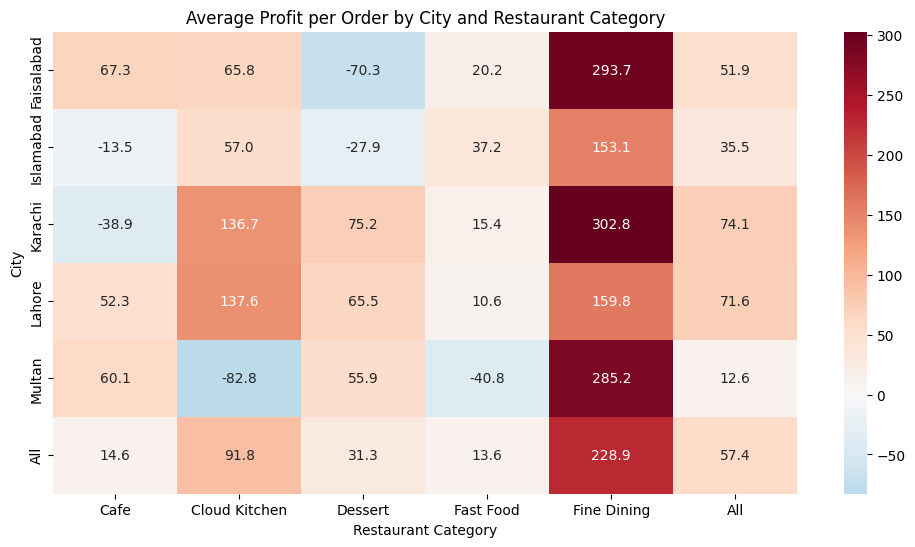

Most profitable combination: ('Karachi', 'Fine Dining')
Average profit per order: 302.8
Top revenue-generating combination: ('Lahore', 'Cloud Kitchen')
Lahore × Cloud Kitchen revenue: 449766.6453946938
Karachi × Fine Dining revenue: 371893.0


In [22]:
#Task 5
profit_pivot = pd.pivot_table(
    df,
    index='city',
    columns='restaurant_category',
    values='profit_per_order',
    aggfunc='mean',
    margins=True
)

display(profit_pivot)

plt.figure(figsize=(12, 6))
sns.heatmap(
    profit_pivot,
    annot=True,
    fmt=".1f",
    cmap='RdBu_r',
    center=0
)

plt.title("Average Profit per Order by City and Restaurant Category")
plt.xlabel("Restaurant Category")
plt.ylabel("City")
plt.show()

profit_combinations = profit_pivot.drop(index='All').drop(columns='All')
best_profit = profit_combinations.stack().idxmax()
best_profit_value = profit_combinations.stack().max()

print("Most profitable combination:", best_profit)
print("Average profit per order:", round(best_profit_value, 2))

revenue_pivot = pd.pivot_table(
    df,
    index='city',
    columns='restaurant_category',
    values='order_value',
    aggfunc='sum'
)

best_revenue = revenue_pivot.stack().idxmax()

print("Top revenue-generating combination:", best_revenue)

lahore_cloud = df[
    (df['city'] == 'Lahore') &
    (df['restaurant_category'] == 'Cloud Kitchen')
]['order_value'].sum()

karachi_fine = df[
    (df['city'] == 'Karachi') &
    (df['restaurant_category'] == 'Fine Dining')
]['order_value'].sum()

print("Lahore × Cloud Kitchen revenue:", lahore_cloud)
print("Karachi × Fine Dining revenue:", karachi_fine)

# Karachi × Fine Dining is the most profitable combination per order, but Lahore × Cloud Kitchen generates the highest total revenue,
# showing that high profitability per order and high total revenue point to different combinations.

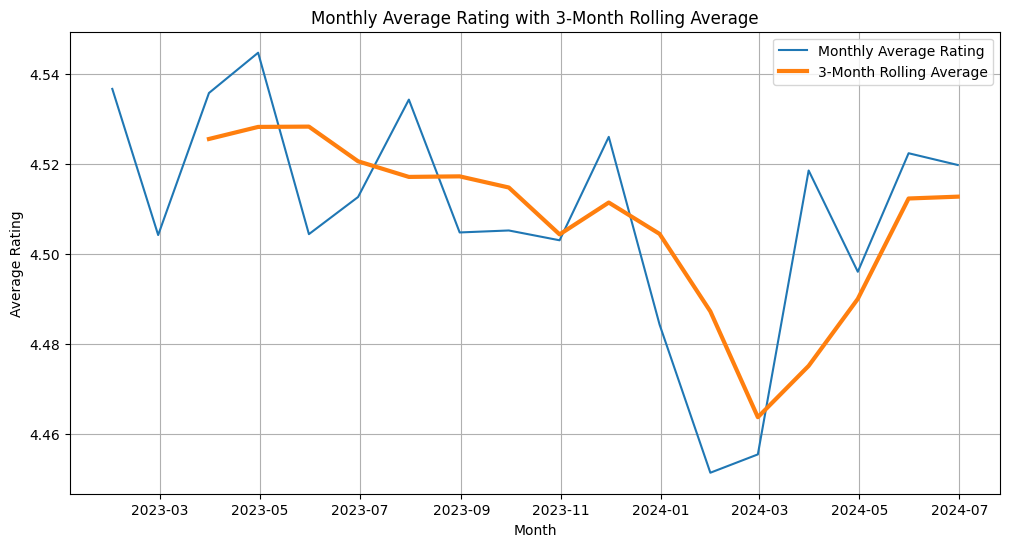

In [23]:
#Task 6
df['order_date'] = pd.to_datetime(df['order_date'])

df_time = df.set_index('order_date')

monthly_rating = df_time['rating'].resample('ME').mean()

rolling_rating = monthly_rating.rolling(window=3).mean()

plt.figure(figsize=(12, 6))

plt.plot(monthly_rating, label='Monthly Average Rating')
plt.plot(rolling_rating, label='3-Month Rolling Average', linewidth=3)

plt.title("Monthly Average Rating with 3-Month Rolling Average")
plt.xlabel("Month")
plt.ylabel("Average Rating")
plt.legend()
plt.grid(True)

plt.show()

# Customer satisfaction shows an overall downward trend from mid-2023 to around March 2024 once the month-to-month noise is smoothed out,
# followed by a recovery through July 2024. The raw monthly line is much more volatile, so it could make the overall decline
# and subsequent recovery less obvious

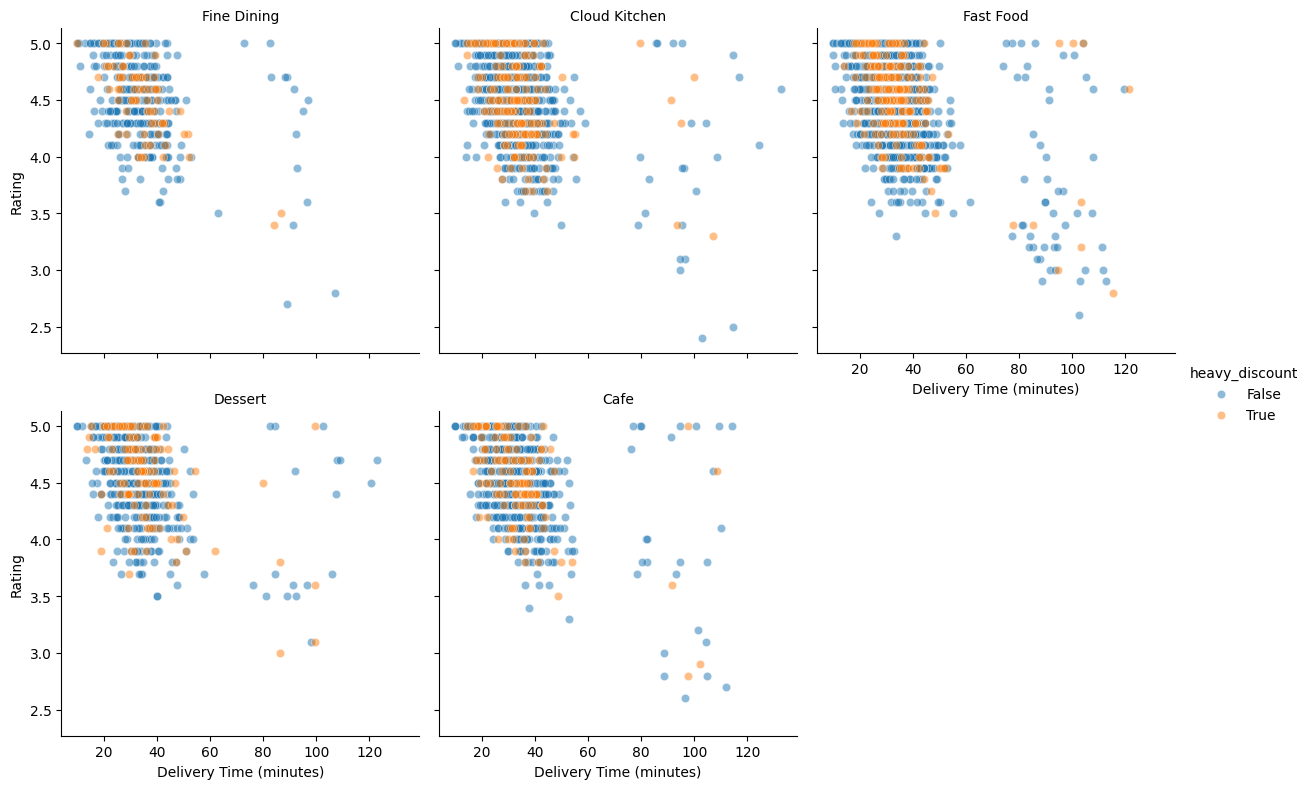

In [24]:
#Task 7
df['heavy_discount'] = df['discount_percent'] > 20

g = sns.FacetGrid(
    df,
    col='restaurant_category',
    hue='heavy_discount',
    col_wrap=3,
    height=4
)

g.map(sns.scatterplot, 'delivery_time_min', 'rating', alpha=0.5)

g.add_legend()
g.set_axis_labels("Delivery Time (minutes)", "Rating")
g.set_titles("{col_name}")

plt.show()

Best rating despite unusually long delivery:
delivery_time_min      79.5
rating                  5.0
city                 Lahore
Name: 143, dtype: object

Worst rating despite unusually fast delivery:
delivery_time_min         19.0
rating                     3.9
city                 Islamabad
Name: 3114, dtype: object


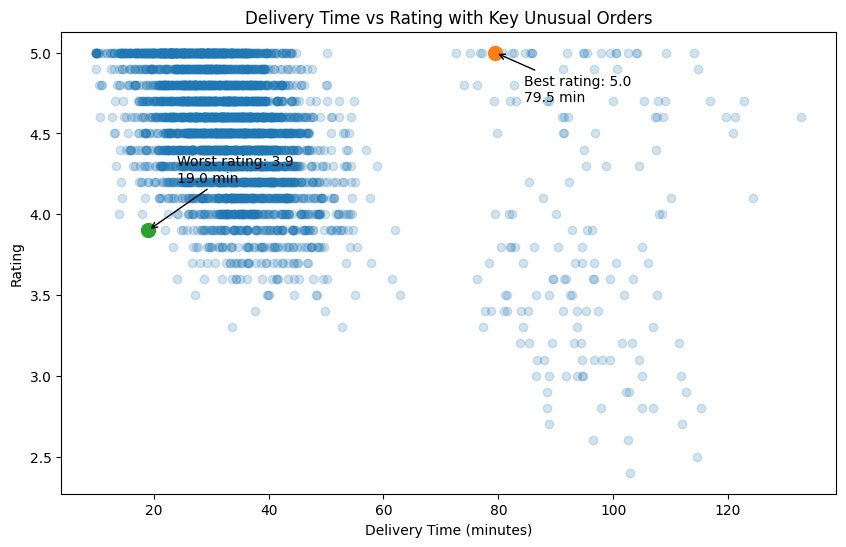

In [25]:
#Task 8
long_threshold = df['delivery_time_min'].quantile(0.95)
fast_threshold = df['delivery_time_min'].quantile(0.05)

long_orders = df[df['delivery_time_min'] >= long_threshold]
best_long = long_orders.loc[long_orders['rating'].idxmax()]

fast_orders = df[df['delivery_time_min'] <= fast_threshold]
worst_fast = fast_orders.loc[fast_orders['rating'].idxmin()]

print("Best rating despite unusually long delivery:")
print(best_long[['delivery_time_min', 'rating', 'city']])

print("\nWorst rating despite unusually fast delivery:")
print(worst_fast[['delivery_time_min', 'rating', 'city']])

plt.figure(figsize=(10, 6))

plt.scatter(
    df['delivery_time_min'],
    df['rating'],
    alpha=0.2
)

plt.scatter(
    best_long['delivery_time_min'],
    best_long['rating'],
    s=100
)

plt.annotate(
    f"Best rating: {best_long['rating']:.1f}\n{best_long['delivery_time_min']:.1f} min",
    xy=(best_long['delivery_time_min'], best_long['rating']),
    xytext=(best_long['delivery_time_min'] + 5, best_long['rating'] - 0.3),
    arrowprops=dict(arrowstyle='->')
)

plt.scatter(
    worst_fast['delivery_time_min'],
    worst_fast['rating'],
    s=100
)

plt.annotate(
    f"Worst rating: {worst_fast['rating']:.1f}\n{worst_fast['delivery_time_min']:.1f} min",
    xy=(worst_fast['delivery_time_min'], worst_fast['rating']),
    xytext=(worst_fast['delivery_time_min'] + 5, worst_fast['rating'] + 0.3),
    arrowprops=dict(arrowstyle='->')
)

plt.title("Delivery Time vs Rating with Key Unusual Orders")
plt.xlabel("Delivery Time (minutes)")
plt.ylabel("Rating")
plt.show()

# Transparency (alpha=0.2) was chosen because the dataset contains 4,200 orders, 
# creating moderate overplotting from repeated rating values, while alpha allows overlapping points to remain visible.